# Clasificación automática de minerales a partir de descriptores de imagen
### Validación sin fuga de información y reducción de dimensión

**Modelos y Simulación de Sistemas II — Proyecto de aula (Aprendizaje supervisado) · Universidad de Antioquia · 2026-2**

Este cuaderno **reproduce todas las tablas, figuras y cifras** del informe en formato IEEE (`informe/informe_ieee.pdf`) y sigue la misma estructura que pide la guía del proyecto:

| Sección | Contenido |
|---|---|
| 1 | Descripción del problema: contexto, composición de la base de datos y paradigma de aprendizaje |
| 2 | Estado del arte (siete artículos de revista) |
| 3 | Metodología de validación (sub/sobremuestreo, validación sin fuga, intervalos de confianza) |
| 4 | Entrenamiento y evaluación de cinco modelos (hiperparámetros, métricas, entrenamiento/validación/prueba) |
| 5 | Reducción de dimensión: análisis individual de variables, selección, PCA y UMAP, y discusión |
| 6 | Conclusiones |
| 7 | Reproducibilidad |

**Cómo ejecutarlo.** Desde la carpeta `notebooks/`: `jupyter lab proyecto_minerales.ipynb` y *Run All*. Los cálculos costosos (mallas de hiperparámetros, validación repetida, reducción) están guardados en `results/cache/`; con `FORCE = False` el cuaderno los reutiliza y termina en menos de un minuto. Con `FORCE = True` recalcula todo con las mismas semillas (del orden de 35 min con 2 núcleos).

**Origen de los datos.** Los 1835 descriptores ya extraídos (`data/features_v2.joblib`) provienen del trabajo previo de Procesamiento Digital de Imágenes del mismo equipo (repositorio `Mista299/clasificador-minerales-pdi-udea-2026-2`), calculados sobre fotografías del banco público `tedqc/mineral-dataset` de Hugging Face.

In [1]:
import os, sys, time, platform, warnings, json
from pathlib import Path
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# --- rutas: el cuaderno vive en notebooks/; el código, en src/
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
os.environ["MYS2_ROOT"] = str(ROOT)
sys.path.insert(0, str(ROOT / "src"))
import mys2_paths as P, mys2_data as D, mys2_core as C, mys2_exp as E, figstyle as F
import fig_individual, fig_embed, fig_hyper, fig_confusion, fig_reduction

FORCE = False            # True = recalcular todo (≈ 35 min); False = reutilizar results/cache
F.setup(); F.OUTDIR = str(P.FIGS)
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)
T0 = time.time()
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__)
import sklearn, scipy, matplotlib
print("scikit-learn", sklearn.__version__, "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__)
print("Semilla global:", C.SEED, "| validación:", f"{C.N_SPLITS} pliegues × {C.N_REPEATS} repeticiones")

Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5
scikit-learn 1.9.1 | scipy 1.18.1 | matplotlib 3.11.2
Semilla global: 2026 | validación: 5 pliegues × 3 repeticiones


---
## 1. Descripción del problema

### 1.A Contexto y utilidad de una solución de aprendizaje automático

Identificar minerales a partir de fotografías es una tarea frecuente en geología, minería y educación, y hoy depende en buena parte del criterio visual de un experto (color, brillo, textura). Ese criterio es limitado: en un problema afín, tres gemólogos expertos alcanzaron entre 42.6 y 66.9 % de exactitud, por debajo del 69.4 % de un Random Forest entrenado con descriptores de color y textura (Chow y Reyes-Aldasoro, 2022), y ya existen aplicaciones móviles de identificación basadas en aprendizaje profundo (Zeng et al., 2021). Una solución de aprendizaje automático ofrece una clasificación **rápida, repetible y de bajo costo computacional**, útil como apoyo en campo, en la clasificación de muestras y en la enseñanza de la mineralogía.

Aquí se aborda una versión acotada y resoluble con las técnicas del curso: distinguir **cuatro minerales de aspecto común** (cuarzo, pirita, malaquita y hematita) con descriptores clásicos de imagen, y responder dos preguntas:

1. ¿Qué desempeño puede esperarse de cada familia de modelos cuando la validación está **libre de fuga de información**?
2. ¿Puede reducirse la complejidad del modelo final sin perder desempeño?

**Objetivo general.** Construir y evaluar con rigor un clasificador supervisado de cuatro minerales a partir de descriptores de imagen.
**Objetivos específicos.** (O1) Caracterizar la base de datos y justificar el paradigma de aprendizaje; (O2) entrenar y comparar cinco modelos con mallas de hiperparámetros explícitas y métricas con intervalos de confianza; (O3) analizar la reducción de dimensión (análisis individual de variables, PCA y UMAP) y su efecto sobre los dos mejores modelos.

### 1.B Composición de la base de datos

Las imágenes provienen del banco público `tedqc/mineral-dataset` (Hugging Face; 62 088 fotografías y 781 etiquetas). El trabajo previo de PDI seleccionó **60 imágenes originales por clase** (240 en total: 168 de entrenamiento, 36 de validación y 36 de prueba) y generó **48 copias aumentadas por clase** a partir de las originales de entrenamiento (rotación ±15°, volteo, brillo/contraste, ruido, desenfoque y compresión JPEG). Cada imagen se redimensiona a 128 × 128 px, se suaviza, se ecualiza (CLAHE sobre L) y se resume en **1835 variables numéricas** (HOG, color, Gabor, LBP, GLCM y momentos de Hu).

In [2]:
d = D.load(P.DATA)
X, y, role, is_aug, group = d["X"], d["y"], d["role"], d["is_aug"], d["group"]
names, fam = np.array(d["names"]), np.array(d["family"])
n, p = X.shape
print(f"n = {n} filas (muestras)   |   p = {p} variables   |   K = {len(D.CLASSES)} clases: {D.CLASSES}")

# --- composición por partición y clase (filas)
part = np.where(role == "test", "Prueba (test)", np.where(role == "val", "Validación", np.where(is_aug, "Entrenamiento – aumentadas", "Entrenamiento – originales")))
comp = pd.crosstab(part, np.array(D.CLASSES)[y], margins=True, margins_name="Total")[D.CLASSES + ["Total"]]
print("\nFilas por partición y clase:")
display_df = comp.loc[["Entrenamiento – originales", "Entrenamiento – aumentadas", "Validación", "Prueba (test)", "Total"]]
display_df

n = 432 filas (muestras)   |   p = 1835 variables   |   K = 4 clases: ['cuarzo', 'pirita', 'malaquita', 'hematita']

Filas por partición y clase:


col_0,cuarzo,pirita,malaquita,hematita,Total
row_0,,,,,
Entrenamiento – originales,42,42,42,42,168
Entrenamiento – aumentadas,48,48,48,48,192
Validación,9,9,9,9,36
Prueba (test),9,9,9,9,36
Total,108,108,108,108,432


In [3]:
# --- datos faltantes, tipos y codificación de las variables
print("Valores faltantes (NaN):", int(np.isnan(X).sum()), "| infinitos:", int(np.isinf(X).sum()),
      "| columnas constantes:", int((X.std(0) == 0).sum()), "| filas duplicadas:", int(len(X) - len(np.unique(X, axis=0))))
print("=> No hay datos faltantes: no se aplica ninguna imputación.\n")
sig = {"HOG": "histogramas de gradientes orientados: 9 orientaciones, celdas de 16×16 px, bloques 2×2 (49 bloques); reales en [0,1]",
       "Color": "media, desviación y asimetría de cada canal de HSV y CIELAB; reales (escala de 8 bits de OpenCV)",
       "Gabor": "media y desviación de la respuesta a 4 orientaciones × 2 longitudes de onda (λ = 8, 16 px); reales positivos",
       "LBP": "histograma normalizado de patrones binarios locales uniformes (P=8, R=1); reales con suma 1",
       "GLCM": "contraste, disimilitud, homogeneidad, energía y correlación en 4 ángulos (distancia 1, 32 niveles); reales",
       "Hu": "7 momentos invariantes del contorno mayor de la máscara de Otsu, como −sgn(h)·log10|h| (acotados a ±30)"}
tab_vars = pd.DataFrame([{"Familia": f, "n variables": int((fam == f).sum()), "Tipo": "numérica continua",
                          "Mín.": float(X[:, fam == f].min()), "Máx.": float(X[:, fam == f].max()), "Significado / codificación": sig[f]}
                         for f, _, _ in D.FAMILIES]).set_index("Familia")
print("Todas las variables de entrada son numéricas continuas (no hay categóricas ⇒ no se usa one-hot).")
print("Se estandarizan con z=(x−μ)/σ, con μ y σ estimados SOLO con el entrenamiento de cada partición.")
print("La etiqueta se codifica como entero: " + ", ".join(f"{c}={i}" for i, c in enumerate(D.CLASSES)) + ".\n")
tab_vars

Valores faltantes (NaN): 0 | infinitos: 0 | columnas constantes: 0 | filas duplicadas: 0
=> No hay datos faltantes: no se aplica ninguna imputación.

Todas las variables de entrada son numéricas continuas (no hay categóricas ⇒ no se usa one-hot).
Se estandarizan con z=(x−μ)/σ, con μ y σ estimados SOLO con el entrenamiento de cada partición.
La etiqueta se codifica como entero: cuarzo=0, pirita=1, malaquita=2, hematita=3.



,n variables,Tipo,Mín.,Máx.,Significado / codificación
Familia,,,,,
HOG,1764,numérica continua,0.000000,1.000000,"histogramas de gradientes orientados: 9 orientaciones, celdas de 16×16 px, bloques 2×2 (49 bloques); reales en [0,1]"
Color,18,numérica continua,-5.302250,248.979553,"media, desviación y asimetría de cada canal de HSV y CIELAB; reales (escala de 8 bits de OpenCV)"
Gabor,16,numérica continua,172.091064,13926.576172,"media y desviación de la respuesta a 4 orientaciones × 2 longitudes de onda (λ = 8, 16 px); reales positivos"
LBP,10,numérica continua,0.000549,0.848022,"histograma normalizado de patrones binarios locales uniformes (P=8, R=1); reales con suma 1"
GLCM,20,numérica continua,0.063490,11.925042,"contraste, disimilitud, homogeneidad, energía y correlación en 4 ángulos (distancia 1, 32 niveles); reales"
Hu,7,numérica continua,-30.000000,30.000000,"7 momentos invariantes del contorno mayor de la máscara de Otsu, como −sgn(h)·log10|h| (acotados a ±30)"


**Análisis exploratorio.** Se resumen el balance de clases, la escala, la asimetría y la redundancia de las variables (con las 204 imágenes originales de desarrollo, que son independientes entre sí).

In [4]:
from scipy import stats
o = (role != "test") & ~is_aug                       # 204 originales de desarrollo
Xo, yo = X[o], y[o]
print("Balance de clases (originales de desarrollo):", dict(zip(D.CLASSES, np.bincount(yo))), "| todas las filas:", dict(zip(D.CLASSES, np.bincount(y))))
sd, sk = Xo.std(0), np.abs(stats.skew(Xo, axis=0))
rows = []
for f, a, b in D.FAMILIES:
    R_ = np.corrcoef(Xo[:, a:b].T); iu = np.triu_indices(b - a, 1)
    rows.append({"Familia": f, "n": b - a, "Mínimo": X[:, a:b].min(), "Máximo": X[:, a:b].max(), "Desv. estándar mediana": np.median(sd[a:b]),
                 "% con |asimetría|>1": 100 * np.mean(sk[a:b] > 1), "Pares con |ρ|≥0.95": int((np.abs(R_[iu]) >= 0.95).sum()) if b - a > 1 else 0})
eda = pd.DataFrame(rows).set_index("Familia")
print(f"Razón entre la mayor y la menor desviación estándar: {sd.max() / sd[sd > 0].min():.1e}  ⇒ hay que estandarizar.")
print(f"Variables con |asimetría| > 1: {int((sk > 1).sum())} de {p} ({100 * np.mean(sk > 1):.0f} %)")
eda.round(3)

Balance de clases (originales de desarrollo): {'cuarzo': np.int64(51), 'pirita': np.int64(51), 'malaquita': np.int64(51), 'hematita': np.int64(51)} | todas las filas: {'cuarzo': np.int64(108), 'pirita': np.int64(108), 'malaquita': np.int64(108), 'hematita': np.int64(108)}
Razón entre la mayor y la menor desviación estándar: 4.1e+05  ⇒ hay que estandarizar.
Variables con |asimetría| > 1: 764 de 1835 (42 %)


,n,Mínimo,Máximo,Desv. estándar mediana,% con |asimetría|>1,Pares con |ρ|≥0.95
Familia,,,,,,
HOG,1764,0.000,1.000,0.089,41.837,332
Color,18,-5.302,248.980,3.328,44.444,3
Gabor,16,172.091,13926.576,397.839,50.000,34
LBP,10,0.001,0.848,0.018,0.000,7
GLCM,20,0.063,11.925,0.215,20.000,30
Hu,7,-30.000,30.000,9.598,85.714,8


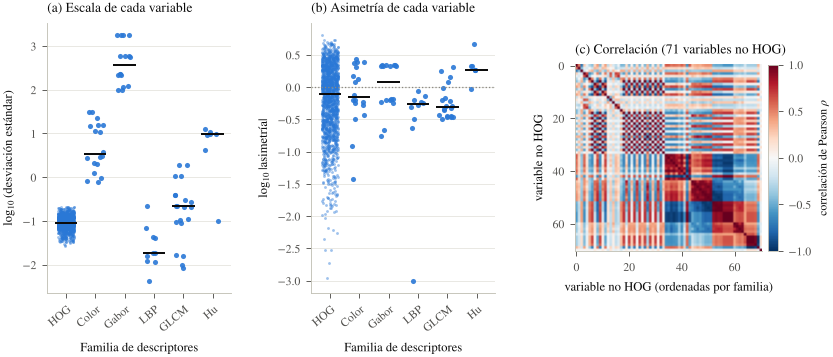

In [5]:
# Figura exploratoria: (a) escala, (b) asimetría por familia y (c) correlación entre las 71 variables no HOG
fams = [f for f, _, _ in D.FAMILIES]; rng = np.random.default_rng(0)
fig, axs = plt.subplots(1, 3, figsize=(F.COL2, 2.7), gridspec_kw=dict(width_ratios=[1, 1, 1.1], wspace=0.42))
for ax, vals, yl, ttl in ((axs[0], np.log10(np.where(sd > 0, sd, np.nan)), r"$\log_{10}$(desviación estándar)", "(a) Escala de cada variable"),
                          (axs[1], np.log10(np.clip(sk, 1e-3, None)), r"$\log_{10}$|asimetría|", "(b) Asimetría de cada variable")):
    for i, f in enumerate(fams):
        v = vals[fam == f]
        ax.scatter(i + rng.uniform(-.28, .28, len(v)), v, s=2.5 if f == "HOG" else 8, color=F.BLUE, alpha=.45 if f == "HOG" else .9, linewidths=0)
        ax.plot([i - .35, i + .35], [np.nanmedian(v)] * 2, color=F.INK, lw=1.1)
    ax.set_xticks(range(6)); ax.set_xticklabels(fams, rotation=40, ha="right", rotation_mode="anchor"); ax.set_ylabel(yl); ax.set_title(ttl, loc="left")
    ax.set_xlabel("Familia de descriptores"); ax.grid(axis="x", visible=False)
axs[1].axhline(0, color=F.MUTED, lw=.7, ls=":")
cm = np.flatnonzero(fam != "HOG"); Rc = np.corrcoef(Xo[:, cm].T)
im = axs[2].imshow(Rc, cmap="RdBu_r", vmin=-1, vmax=1, aspect="equal")
axs[2].set_title("(c) Correlación (71 variables no HOG)", loc="left"); axs[2].set_xlabel("variable no HOG (ordenadas por familia)"); axs[2].set_ylabel("variable no HOG")
axs[2].grid(False); fig.colorbar(im, ax=axs[2], fraction=0.046, pad=0.03).set_label(r"correlación de Pearson $\rho$", fontsize=6.5)
plt.show()

### 1.C Paradigma de aprendizaje

Se elige **aprendizaje supervisado** y, en concreto, **clasificación multiclase** con $K=4$ clases balanceadas: cada imagen tiene una etiqueta conocida (el nombre del mineral) y el objetivo es predecirla para imágenes nuevas. Se descartan el aprendizaje no supervisado (las clases ya están definidas), el semisupervisado (todas las imágenes están etiquetadas) y el aprendizaje por refuerzo (no hay interacción secuencial). Con unas 200 imágenes originales se prefieren descriptores diseñados a mano y modelos clásicos a redes convolucionales de extremo a extremo, que tienden a sobreajustar con tan pocos datos y quedan fuera de las técnicas del curso; además, los descriptores son interpretables, lo que permite analizar qué variables discriminan (sección 5). Las técnicas no supervisadas (PCA, UMAP) solo se usan como **preprocesamiento dentro de un esquema supervisado**.

---
## 2. Estado del arte

Siete artículos de revista sobre clasificación **supervisada** de minerales a partir de imágenes. Ninguno usa la base de datos de este trabajo (publicada en 2025), por lo que se eligieron los que abordan el mismo problema de aprendizaje (fotografías o imágenes de minerales y gemas) y, entre ellos, los que comparan clasificadores clásicos.

| Referencia (revista, año) | Datos | Paradigma y técnicas | Validación | Métricas | Mejor resultado reportado |
|---|---|---|---|---|---|
| Chow y Reyes-Aldasoro, *Minerals* 12(1):60, 2022 | 2 326 fotos de gemas, 68 clases | Supervisado. Descriptores manuales de color y textura (histogramas RGB/HSV/CIELAB, GLCM, LBP) con LogReg, LDA, k-NN, árbol, RF, Bayes ingenuo y SVM; ResNet-18/50; SMOTE | Test fijo (284 imágenes); CV de 5 pliegues para hiperparámetros | Exactitud, top-5 | RF con histograma RGB y LBP: 69.4 % (top-5 96.5 %); expertos: 42.6–66.9 % |
| Maitre, Bouchard y Bédard, *Computers & Geosciences* (Elsevier) 130:84–93, 2019 | Imágenes de microscopio óptico de granos de arena; 8 minerales y fondo | Supervisado. Descriptores de color (estadísticos por canal en RGB/HSV/Lab, picos del histograma) y textura por superpíxel; CART, k-NN y RF | Una partición 70/30; sin CV | Exactitud, kappa de Cohen, P/R/F1 por clase | RF: exactitud 0.82 y kappa 0.73 (9 clases); 0.89 y 0.86 con las 5 clases más abundantes |
| Liu et al., *Minerals* 9(9):516, 2019 | 4 178 fotos, 12 minerales | Supervisado. Inception-v3 (transferencia) con realce de textura y modelo de color (K-means); línea base SVM y RF sobre HOG | 20 imágenes por clase para test; sin CV | Top-1, top-3 | 74.2 % top-1 y 99.0 % top-3; SVM-HOG 32.8 %, RF-HOG 31.2 % |
| Zhang et al., *Sensors* 19(18):3914, 2019 | Imágenes microscópicas, 4 minerales | Supervisado. Inception-v3 como extractor (2048 variables) y LR, SVM, RF, k-NN, MLP, Bayes gaussiano; apilamiento | CV de 10 pliegues (individuales) y de 5 (apilado) | Exactitud media y desviación entre pliegues | SVM 90.6 %; apilado 90.9 %; Bayes gaussiano ≈ 78 % |
| Jia et al., *Minerals* 11(12):1354, 2021 | 14 986 fotos, 22 minerales | Supervisado. ResNet-50 con fusión de capas y pérdida top-k ponderada (minería de ejemplos difíciles) | CV de 10 pliegues (9:1) | Top-1, mAP (media por clase de top-1) | 88.01 % top-1; 87.15 % mAP |
| Zeng et al., *Minerals* 11(5):506, 2021 | 183 688 fotos, 36 minerales | Supervisado. EfficientNet-B4 con dureza de Mohs concatenada a las variables de imagen | Partición fija 10:1:1 | Top-1, top-5 | 90.6 % top-1 y 99.6 % top-5 (solo imagen: 78.3 % y 95.5 %) |
| Long y Zhou, *Informatica* 49(34):87–108, 2025 | 5 536 fotos, 7 minerales (incl. cuarzo, malaquita, pirita) | Supervisado. YOLOv8-CLS preentrenado con aumentación; ResNet-50/101 como comparación | Partición fija 3 872/1 106/558 y un segundo conjunto de otra fuente | Top-1, top-5 | 90.7 % top-1 en test; baja a 80.2 % en el otro conjunto |

**Métricas no vistas en clase.** La *exactitud top-k* cuenta un acierto si la clase verdadera está entre las $k$ de mayor probabilidad:
$\mathrm{Top}\text{-}k=\frac1N\sum_{i=1}^{N}\mathbb 1\!\left[y_i\in\mathcal T_k(\mathbf p_i)\right]$ (con $K=4$ es poco informativa). Jia et al. llaman *mAP* a la media por clase de la exactitud top-1, $\frac1K\sum_c\frac1{N_c}\sum_{i:y_i=c}\mathbb 1[\hat y_i=c]$, es decir, el *recall* macro. El *kappa de Cohen* corrige la exactitud por el acierto esperado al azar: $\kappa=(p_o-p_e)/(1-p_e)$, con $p_o=\mathrm{Acc}$ y $p_e=\sum_c\pi_c\hat\pi_c$ (proporciones de la clase $c$ entre las etiquetas verdaderas y las predichas).

**Qué falta en la literatura y qué aporta este trabajo.** Los trabajos revisados reportan cifras puntuales: solo Zhang et al. informan la desviación entre pliegues, ninguno informa intervalos de confianza, cinco de los siete evalúan con una única partición fija y los resultados de Long y Zhou muestran cuánto puede caer el desempeño al cambiar de fuente de imágenes. Este trabajo aporta (i) una validación repetida y agrupada por imagen de origen, con intervalos de confianza, (ii) la comparación de los cinco tipos de modelo del curso con mallas explícitas y (iii) un análisis de reducción de dimensión.

---
## 3. Metodología de validación

* **Particiones.** Las 36 imágenes de prueba (9 por clase) se reservan y no se usan para ninguna decisión. Las 204 originales restantes (51 por clase) y las 192 copias aumentadas forman el *conjunto de desarrollo* (396 filas).
* **Sobremuestreo (aumentación).** El banco ya está balanceado, por lo que no hay submuestreo ni SMOTE. Las copias aumentadas **no son independientes de su original**: si copia y original quedan en lados distintos de una partición, la validación se contamina (*fuga de información*).
* **Validación cruzada sin fuga.** Validación cruzada estratificada de 5 pliegues repetida 3 veces ($J=15$ estimaciones) sobre las 204 *originales*. En cada pliegue, el entrenamiento contiene las originales del pliegue y **solo las copias de esas originales**; la validación contiene únicamente originales. El estandarizador (y luego la selección de variables, PCA y UMAP) se ajusta solo con el entrenamiento del pliegue.
* **Intervalos de confianza.** Los $J$ puntajes no son independientes, así que se usa el intervalo t corregido de Nadeau y Bengio: $\bar s\pm t_{J-1,0.975}\sqrt{(1/J+n_{va}/n_{tr})\hat\sigma^2}$. En prueba ($N=36$): intervalo de Wilson para la exactitud y *bootstrap* percentil (2000 remuestreos) para el F1 macro.
* **Métricas.** Exactitud y **F1 macro** (promedio del F1 de cada clase), este último como criterio de selección: castiga que un modelo acierte unas clases a costa de otras. Además, la matriz de confusión.

In [6]:
splits = C.make_splits(d)                       # 15 particiones sin fuga
n_tr = float(np.mean([s["n_tr_orig"] for s in splits])); n_va = float(np.mean([len(s["val"]) for s in splits]))
print(f"{len(splits)} particiones | originales en entrenamiento ≈ {n_tr:.0f} (+ sus copias) | validación ≈ {n_va:.0f} originales | n_va/n_tr = {n_va / n_tr:.2f}")

# Comprobación automática de ausencia de fuga: ninguna imagen de validación aparece, ni como copia, en el entrenamiento
for s in splits:
    assert not is_aug[s["val"]].any()                                  # la validación solo tiene originales
    assert not set(group[s["val"]]) & set(group[s["train"]])           # ni la imagen ni sus copias están en el entrenamiento
    assert (role[s["val"]] != "test").all() and (role[s["train"]] != "test").all()   # la prueba no se toca
print("OK: ninguna de las 15 particiones tiene fuga y la prueba no se usa.")

# Para comparar: la CV 'ingenua' (mezcla originales y copias al azar, como en el trabajo previo)
naive = C.make_naive_splits(d)
leak = [np.mean(np.isin(group[s["val"]], group[s["train"]])) for s in naive]
print(f"CV ingenua: en promedio el {100 * np.mean(leak):.0f} % de las filas de validación tiene su imagen de origen (o una copia) en el entrenamiento.")

15 particiones | originales en entrenamiento ≈ 163 (+ sus copias) | validación ≈ 41 originales | n_va/n_tr = 0.25
OK: ninguna de las 15 particiones tiene fuga y la prueba no se usa.
CV ingenua: en promedio el 85 % de las filas de validación tiene su imagen de origen (o una copia) en el entrenamiento.


---
## 4. Entrenamiento y evaluación

Se comparan cinco modelos, uno por familia: **regresión logística** (paramétrico), **k-NN** (no paramétrico), **Random Forest** (conjunto de árboles), **perceptrón multicapa** (red neuronal) y **SVM**, con scikit-learn. La tabla siguiente es la malla de cada hiperparámetro (se amplió donde el óptimo quedaba en el borde).

In [7]:
def fmt(v):
    return ", ".join(("sin límite" if x is None else (str(x) if not isinstance(x, float) else f"{x:g}")) for x in v)
rows = []
for m, g in C.GRIDS.items():
    for sub in (g if isinstance(g, list) else [g]):
        for h, vals in sub.items():
            rows.append({"Modelo": m, "Hiperparámetro": h, "Valores": fmt(vals)})
tab_grid = pd.DataFrame(rows)
n_cfg = {m: len(C.expand_grid(g)) for m, g in C.GRIDS.items()}
print("Configuraciones por modelo:", n_cfg, "| total:", sum(n_cfg.values()), "| × 15 particiones =", 15 * sum(n_cfg.values()), "ajustes")
print("Fijos: LogReg multinomial L2 (máx. 3000 iter.); MLP con ReLU, Adam, tasa 1e-3, máx. 500 épocas; semilla", C.SEED)
tab_grid

Configuraciones por modelo: {'Regresión logística': 7, 'k-NN': 16, 'Random Forest': 40, 'MLP': 28, 'SVM': 29} | total: 120 | × 15 particiones = 1800 ajustes
Fijos: LogReg multinomial L2 (máx. 3000 iter.); MLP con ReLU, Adam, tasa 1e-3, máx. 500 épocas; semilla 2026


,Modelo,Hiperparámetro,Valores
0,Regresión logística,C,"0.0001, 0.001, 0.01, 0.1, 1, 10, 100"
1,k-NN,n_neighbors,"1, 3, 5, 7, 9, 11, 15, 21"
2,k-NN,weights,"uniform, distance"
3,Random Forest,n_estimators,"100, 300"
4,Random Forest,max_depth,"3, 5, 10, sin límite"
5,Random Forest,max_features,"log2, sqrt, 0.1, 0.3"
6,Random Forest,n_estimators,100
7,Random Forest,max_depth,"3, 5, 10, sin límite"
8,Random Forest,max_features,"0.6, 1"
9,MLP,hidden_layer_sizes,"(32,), (64,), (128,), (64, 32)"


In [8]:
t0 = time.time()
grids = E.run_grids(d, str(P.CACHE), force=FORCE)           # {modelo: [resultado por configuración]}
print(f"({time.time() - t0:.0f} s)")
best = {m: C.best_of(r) for m, r in grids.items()}
pd.DataFrame([{"Modelo": m, "Mejor configuración": b["params"], "F1 val.": f"{b['f1_mean']:.3f} ± {b['f1_ci']:.3f}",
               "Exactitud val.": f"{b['acc_mean']:.3f} ± {b['acc_ci']:.3f}", "F1 entren.": round(b["train_f1"], 3)}
              for m, b in best.items()]).set_index("Modelo")

[    0s] Regresión logística    7 configs ( 0 nuevas)  mejor F1=0.604±0.104 acc=0.610 {'C': 10.0}
[    0s] k-NN                  16 configs ( 0 nuevas)  mejor F1=0.512±0.074 acc=0.518 {'n_neighbors': 5, 'weights': 'uniform'}
[    0s] Random Forest         40 configs ( 0 nuevas)  mejor F1=0.832±0.063 acc=0.834 {'n_estimators': 100, 'max_depth': None, 'max_features': 0.3}
[    0s] MLP                   28 configs ( 0 nuevas)  mejor F1=0.622±0.106 acc=0.626 {'hidden_layer_sizes': (32,), 'alpha': 10.0}
[    0s] SVM                   29 configs ( 0 nuevas)  mejor F1=0.586±0.108 acc=0.592 {'kernel': 'rbf', 'C': 1000.0, 'gamma': 1e-05}
(0 s)


,Mejor configuración,F1 val.,Exactitud val.,F1 entren.
Modelo,,,,
Regresión logística,{'C': 10.0},0.604 ± 0.104,0.610 ± 0.102,1.00
k-NN,"{'n_neighbors': 5, 'weights': 'uniform'}",0.512 ± 0.074,0.518 ± 0.071,0.74
Random Forest,"{'n_estimators': 100, 'max_depth': None, 'max_features': 0.3}",0.832 ± 0.063,0.834 ± 0.059,1.00
MLP,"{'hidden_layer_sizes': (32,), 'alpha': 10.0}",0.622 ± 0.106,0.626 ± 0.102,1.00
SVM,"{'kernel': 'rbf', 'C': 1000.0, 'gamma': 1e-05}",0.586 ± 0.108,0.592 ± 0.106,1.00


### 4.1 Efecto de los hiperparámetros

Cada panel muestra el F1 macro de validación (media de 15 particiones; banda = IC 95 % de Nadeau–Bengio); la línea punteada es el F1 de entrenamiento.

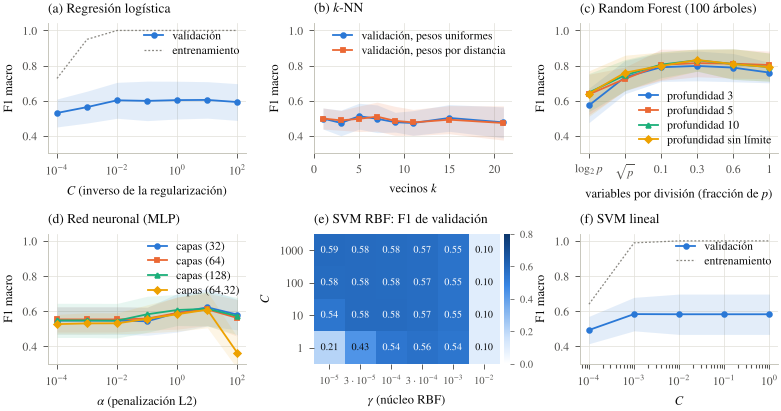

In [9]:
fig = fig_hyper.make(grids)
F.save(fig, "fig_hyper", close=False); plt.show()

**Lectura.**
* *Regresión logística*: con regularización fuerte subajusta; desde $C=10^{-2}$ hay una meseta, mientras el F1 de entrenamiento llega a 1.00 (memoriza: $p\gg n$).
* *k-NN*: ni $k$ ni los pesos cambian el resultado; la distancia euclídea en 1835 dimensiones queda dominada por las 1764 variables HOG, poco discriminantes (sección 5).
* *Random Forest*: el hiperparámetro decisivo es el número de variables por división; solo el 3.9 % de las variables (las 71 no HOG) es informativo, y con pocas variables por nodo rara vez aparecen (se calcula abajo).
* *MLP*: lo que importa es la penalización L2 (óptimo $\alpha=10$); con $\alpha=100$ la red subajusta.
* *SVM*: con núcleo RBF, $\gamma=10^{-2}$ colapsa el F1 (la matriz de núcleo tiende a la identidad); en el resto hay una meseta; el núcleo lineal rinde igual.

In [10]:
from scipy.stats import hypergeom
for mtry, nombre in ((int(np.log2(p)), "log2(p)"), (int(np.sqrt(p)), "sqrt(p)"), (int(0.3 * p), "0.3 p")):
    print(f"max_features = {nombre:8s} = {mtry:4d} variables por división → P(un nodo ve al menos una de las 71 variables no HOG) = {1 - hypergeom.pmf(0, p, 71, mtry):.2f}")

max_features = log2(p)  =   10 variables por división → P(un nodo ve al menos una de las 71 variables no HOG) = 0.33
max_features = sqrt(p)  =   42 variables por división → P(un nodo ve al menos una de las 71 variables no HOG) = 0.81
max_features = 0.3 p    =  550 variables por división → P(un nodo ve al menos una de las 71 variables no HOG) = 1.00


### 4.2 Desempeño: entrenamiento, validación y prueba

Para cada modelo (con su mejor configuración) se calculan: la validación sin fuga (media ± IC 95 %), la **validación con fuga** (CV ingenua sobre las 360 filas de entrenamiento mezcladas), la validación **sin aumentación**, el ajuste final sobre todo el desarrollo y la evaluación en la **prueba** (IC de Wilson y *bootstrap*).

In [11]:
t0 = time.time()
s3 = E.run_final(d, grids, str(P.CACHE), force=FORCE)
print(f"({time.time() - t0:.0f} s)   Ranking por F1 de validación:", s3["ranking"])
rows = []
for m in s3["ranking"]:
    r = s3[m]; v = r["val"]
    rows.append({"Modelo": m, "Exactitud entren.": round(r["train_acc"], 3), "F1 entren.": round(r["train_f1"], 3),
                 "Exactitud val.": f"{v['acc_m'][0]:.3f} ± {v['acc_m'][1]:.3f}", "F1 val.": f"{v['f1_m'][0]:.3f} ± {v['f1_m'][1]:.3f}",
                 "Exactitud test [IC95]": f"{r['test_acc']:.3f} [{r['test_acc_ci'][0]:.2f}, {r['test_acc_ci'][1]:.2f}]",
                 "F1 test [IC95]": f"{r['test_f1']:.3f} [{r['test_f1_ci'][0]:.2f}, {r['test_f1_ci'][1]:.2f}]",
                 "F1 val. CON fuga": round(r["naive"]["f1_m"][0], 3), "F1 val. sin aument.": round(r["noaug"]["f1_m"][0], 3)})
tab_res = pd.DataFrame(rows).set_index("Modelo")
tab_res

(0 s)   Ranking por F1 de validación: ['Random Forest', 'MLP', 'Regresión logística', 'SVM', 'k-NN']


,Exactitud entren.,F1 entren.,Exactitud val.,F1 val.,Exactitud test [IC95],F1 test [IC95],F1 val. CON fuga,F1 val. sin aument.
Modelo,,,,,,,,
Random Forest,1.000,1.00,0.834 ± 0.059,0.832 ± 0.063,"0.778 [0.62, 0.88]","0.779 [0.62, 0.90]",0.883,0.773
MLP,1.000,1.00,0.626 ± 0.102,0.622 ± 0.106,"0.667 [0.50, 0.80]","0.659 [0.48, 0.80]",0.716,0.591
Regresión logística,1.000,1.00,0.610 ± 0.102,0.604 ± 0.104,"0.639 [0.48, 0.78]","0.640 [0.46, 0.78]",0.710,0.585
SVM,1.000,1.00,0.592 ± 0.106,0.586 ± 0.108,"0.528 [0.37, 0.68]","0.522 [0.34, 0.67]",0.745,0.561
k-NN,0.742,0.74,0.518 ± 0.071,0.512 ± 0.074,"0.472 [0.32, 0.63]","0.460 [0.29, 0.60]",0.556,0.520


In [12]:
# Diferencias pareadas (mismos pliegues) con el IC de Nadeau-Bengio
def paired(a, b):
    m, h = C.nb_ci(a - b, n_tr, n_va)
    return f"{m:+.3f} ± {h:.3f}" + ("  (significativa)" if abs(m) > h else "  (no concluyente)")
import itertools
print("Diferencias pareadas de F1 de validación entre los modelos (ordenados de mayor a menor F1):")
for a_, b_ in itertools.combinations(s3["ranking"], 2):
    print(f"  {a_:20s} − {b_:20s}", paired(s3[a_]["val"]["f1"], s3[b_]["val"]["f1"]))
print("\nEfecto de la AUMENTACIÓN (con − sin copias), F1 de validación sin fuga:")
for m in s3["ranking"]:
    print(f"  {m:22s}", paired(s3[m]["val"]["f1"], s3[m]["noaug"]["f1"]))
print("\nOptimismo de la validación CON fuga (F1 ingenuo − F1 sin fuga):")
for m in s3["ranking"]:
    print(f"  {m:22s} {s3[m]['naive']['f1_m'][0] - s3[m]['val']['f1_m'][0]:+.3f}   (F1 en prueba: {s3[m]['test_f1']:.3f})")

Diferencias pareadas de F1 de validación entre los modelos (ordenados de mayor a menor F1):
  Random Forest        − MLP                  +0.210 ± 0.103  (significativa)
  Random Forest        − Regresión logística  +0.228 ± 0.102  (significativa)
  Random Forest        − SVM                  +0.246 ± 0.113  (significativa)
  Random Forest        − k-NN                 +0.320 ± 0.090  (significativa)
  MLP                  − Regresión logística  +0.017 ± 0.055  (no concluyente)
  MLP                  − SVM                  +0.036 ± 0.069  (no concluyente)
  MLP                  − k-NN                 +0.110 ± 0.085  (significativa)
  Regresión logística  − SVM                  +0.018 ± 0.047  (no concluyente)
  Regresión logística  − k-NN                 +0.093 ± 0.085  (significativa)
  SVM                  − k-NN                 +0.074 ± 0.082  (no concluyente)

Efecto de la AUMENTACIÓN (con − sin copias), F1 de validación sin fuga:
  Random Forest          +0.059 ± 0.057  (significa

Prueba — métricas por clase de Random Forest


,precision,recall,f1
cuarzo,0.67,0.89,0.76
pirita,0.75,0.67,0.71
malaquita,1.00,0.89,0.94
hematita,0.75,0.67,0.71


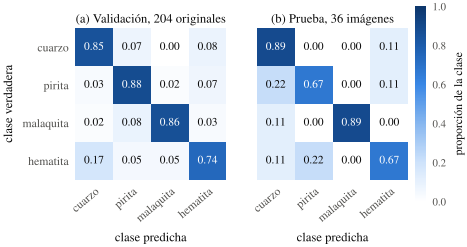

In [13]:
fig = fig_confusion.make(s3)
F.save(fig, "fig_confusion", close=False); plt.show()
best_m = s3["ranking"][0]
print("Prueba — métricas por clase de", best_m)
pd.DataFrame(s3[best_m]["test_per_class"], index=D.CLASSES).round(2)

**Lectura.** El Random Forest es el mejor y su ventaja sobre cada uno de los otros cuatro es estadísticamente significativa; el MLP, la regresión logística y la SVM no se distinguen entre sí (diferencias pareadas no concluyentes) y k-NN, el peor, queda por debajo del MLP y de la regresión logística (significativo), pero no de la SVM. Todos los modelos (salvo k-NN) alcanzan F1 de entrenamiento 1.00: sobreajuste que la regularización de las mallas no elimina. En prueba el orden se conserva, pero con 36 imágenes los IC son anchos y se solapan: la jerarquía se apoya en la validación (204 imágenes × 15 particiones) y la prueba sirve de confirmación. La validación **con fuga** sobreestima el F1 (hasta +0.16) y no concuerda con la prueba; la validación sin fuga sí.

---
## 5. Reducción de dimensión

### 5.1 Análisis individual de las variables

Con las 204 originales de desarrollo (sin copias ni prueba) se calcula, para cada variable: el **índice de discriminación** $\eta^2=SS_B/SS_T$ (razón de correlación; equivale al estadístico $F$ del ANOVA de un factor reescalado a $[0,1]$), su valor $q$ de Benjamini–Hochberg (control de la tasa de falsos descubrimientos), la información mutua con la clase y la **redundancia** (una variable es redundante si su $|\rho|\ge0.95$ con otra más discriminante ya conservada). Son *candidatas a eliminar* las no significativas ($q\ge0.05$) o redundantes.

In [14]:
t0 = time.time()
s2 = E.run_individual(d, str(P.CACHE), force=FORCE)
dfv, tab_ind = s2["df"], s2["tab"]
print(f"({time.time() - t0:.0f} s)  Spearman(η², información mutua) = {s2['spearman']:.2f} | pares con |ρ| ≥ 0.95: {s2['n_pairs_hi']}")
print(f"Variables: {len(dfv)} | no significativas (q ≥ 0.05): {int(dfv.no_significativa.sum())} | significativas pero redundantes: {int((dfv.redundante & ~dfv.no_significativa).sum())}"
      f" | CANDIDATAS A ELIMINAR: {int(dfv.candidata.sum())} ({100 * dfv.candidata.mean():.0f} %) | conservadas: {int((~dfv.candidata).sum())}")
tab_ind.round(3).set_index("familia")

(0 s)  Spearman(η², información mutua) = 0.51 | pares con |ρ| ≥ 0.95: 446
Variables: 1835 | no significativas (q ≥ 0.05): 956 | significativas pero redundantes: 174 | CANDIDATAS A ELIMINAR: 1130 (62 %) | conservadas: 705


,n_vars,eta2_mediana,eta2_max,MI_mediana,pct_signif,n_no_signif,n_redundantes,n_candidatas,n_conservadas
familia,,,,,,,,,
HOG,1764,0.042,0.238,0.059,45.918,954,142,1096,668
Color,18,0.205,0.515,0.165,100.000,0,3,3,15
Gabor,16,0.203,0.255,0.151,100.000,0,11,11,5
LBP,10,0.275,0.322,0.223,100.000,0,4,4,6
GLCM,20,0.303,0.399,0.228,100.000,0,10,10,10
Hu,7,0.123,0.134,0.070,71.429,2,4,6,1


Las 10 variables más discriminantes:


,variable,familia,eta2,MI,q_BH,redundante
0,Color_LAB-a_asim,Color,0.5149,0.3485,0.0,False
1,Color_LAB-a_desv,Color,0.4271,0.3097,0.0,False
2,GLCM_disimilitud_0,GLCM,0.3992,0.2634,0.0,False
3,GLCM_contraste_0,GLCM,0.3895,0.2910,0.0,False
4,GLCM_homogeneidad_0,GLCM,0.3510,0.2431,0.0,True
5,GLCM_contraste_135,GLCM,0.3404,0.2841,0.0,False
6,GLCM_disimilitud_135,GLCM,0.3383,0.1548,0.0,True
7,GLCM_disimilitud_45,GLCM,0.3343,0.1744,0.0,True
8,GLCM_contraste_45,GLCM,0.3279,0.2324,0.0,True
9,Color_LAB-a_media,Color,0.3248,0.4266,0.0,False


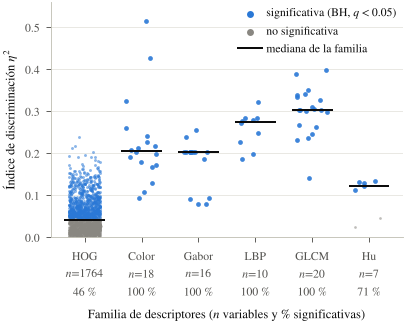

In [15]:
fig = fig_individual.make(dfv)
F.save(fig, "fig_individual", close=False); plt.show()
print("Las 10 variables más discriminantes:")
dfv.sort_values("eta2", ascending=False).head(10)[["variable", "familia", "eta2", "MI", "q_BH", "redundante"]].round(4).reset_index(drop=True)

**Lectura.** La información está concentrada en los 71 descriptores compactos (color, Gabor, LBP, GLCM y Hu), casi todos significativos; de las 1764 variables HOG solo menos de la mitad es significativa y con $\eta^2$ bajo. La redundancia es estructural (las 8 medias de Gabor son idénticas entre sí y a la luminancia media; la energía GLCM es igual en tres ángulos; los momentos de Hu 2–6 están muy correlacionados). Que una variable sea poco discriminante *individualmente* no implica que sea inútil *en conjunto*, así que el efecto real de eliminarlas se mide con los modelos.

### 5.2 Protocolo común de reducción (selección, PCA y UMAP)

Para las tres técnicas se **re-evalúan los dos mejores modelos** (Random Forest y MLP) con la misma validación sin fuga: la reducción se ajusta en cada pliegue **solo con el entrenamiento**; cada modelo se re-ajusta en el espacio reducido con una malla pequeña y las componentes/variables se reestandarizan. El tamaño $k^*$ se elige con un **criterio propio**, la *regla de un error estándar* (Hastie et al.): el menor $k$ cuyo F1 medio de validación está a menos de un error estándar (el de Nadeau–Bengio) del mejor $k$ de la malla. Con $k^*$ se reajusta con todo el desarrollo y se evalúa en la prueba. **Reducción (%)** $=(1835-k^*)/1835$.

In [16]:
def curve_table(res):
    # F1 de validación (media ± IC95) por k, para cada uno de los dos modelos, y k* de la regla de 1 error estándar
    rows = []
    for m in res["models"]:
        sm = res["summary"][m]
        for x in sm["per_k"]:
            rows.append({"modelo": m, "k": ("todas las signif. no redund." if x["k"] == -1 else x["k"]),
                         "F1 val.": f"{x['f1_mean']:.3f} ± {x['f1_ci']:.3f}", "Exactitud val.": round(x["acc_mean"], 3),
                         "k*": "◄" if x["k"] == sm["k_1se"] else "", **{{"var": "var. expl. (media de pliegues)", "n": "n variables (media de pliegues)"}.get(k, k): round(v, 3) for k, v in x["extra"].items()}})
    return pd.DataFrame(rows)

def final_table(res):
    return pd.DataFrame([{"modelo": m, "k*": s["final"]["k"], "reducción %": round(100 * (1835 - s["final"]["k"]) / 1835, 1),
                          "F1 entren.": round(s["final"]["train_f1"], 3),
                          "Exactitud test [IC95]": f"{s['final']['test_acc']:.3f} [{s['final']['test_acc_ci'][0]:.2f}, {s['final']['test_acc_ci'][1]:.2f}]",
                          "F1 test [IC95]": f"{s['final']['test_f1']:.3f} [{s['final']['test_f1_ci'][0]:.2f}, {s['final']['test_f1_ci'][1]:.2f}]",
                          **({"var. explicada": round(s['final']['cumvar'], 3)} if 'cumvar' in s['final'] else {})}
                         for m, s in res["summary"].items()]).set_index("modelo")

def paired_vs_baseline(res):
    for m in res["models"]:
        sm = res["summary"][m]; pk = [x for x in sm["per_k"] if x["k"] == sm["k_1se"]][0]
        print(f"  {m:14s} k*={sm['k_1se']:4d}: F1 reducido − F1 con 1835 variables =", paired(pk["f1"], s3[m]["val"]["f1"]))

### 5.3 Selección de variables por $\eta^2$ (filtro)

In [17]:
t0 = time.time()
r_sel = E.run_reduction(d, "sel", s3, str(P.CACHE), force=FORCE)
print(f"({time.time() - t0:.0f} s)  modelos:", r_sel["models"])
paired_vs_baseline(r_sel)
curve_table(r_sel)

(0 s)  modelos: ['Random Forest', 'MLP']
  Random Forest  k*=  30: F1 reducido − F1 con 1835 variables = +0.001 ± 0.035  (no concluyente)
  MLP            k*=  10: F1 reducido − F1 con 1835 variables = +0.161 ± 0.126  (significativa)


,modelo,k,F1 val.,Exactitud val.,k*,n variables (media de pliegues)
0,Random Forest,5,0.745 ± 0.062,0.750,,
1,Random Forest,10,0.762 ± 0.085,0.768,,
2,Random Forest,15,0.771 ± 0.064,0.775,,
3,Random Forest,20,0.800 ± 0.069,0.801,,
4,Random Forest,30,0.833 ± 0.066,0.835,◄,
5,Random Forest,40,0.835 ± 0.062,0.837,,
6,Random Forest,60,0.831 ± 0.071,0.834,,
7,Random Forest,80,0.835 ± 0.078,0.837,,
8,Random Forest,120,0.837 ± 0.069,0.838,,
9,Random Forest,200,0.845 ± 0.061,0.847,,


In [18]:
final_table(r_sel)

,k*,reducción %,F1 entren.,Exactitud test [IC95],F1 test [IC95]
modelo,,,,,
Random Forest,30,98.4,1.000,"0.750 [0.59, 0.86]","0.750 [0.59, 0.88]"
MLP,10,99.5,0.922,"0.750 [0.59, 0.86]","0.745 [0.58, 0.87]"


### 5.4 PCA

In [19]:
t0 = time.time()
r_pca = E.run_reduction(d, "pca", s3, str(P.CACHE), force=FORCE)
print(f"({time.time() - t0:.0f} s)  modelos:", r_pca["models"])
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
dev = role != "test"
cv = np.cumsum(PCA(svd_solver="full").fit(StandardScaler().fit_transform(X[dev])).explained_variance_ratio_)
print("Componentes necesarios para explicar 80/90/95 % de la varianza (criterio clásico):", [int(np.searchsorted(cv, q) + 1) for q in (0.80, 0.90, 0.95)])
paired_vs_baseline(r_pca)
curve_table(r_pca)

(0 s)  modelos: ['Random Forest', 'MLP']
Componentes necesarios para explicar 80/90/95 % de la varianza (criterio clásico): [104, 169, 229]
  Random Forest  k*=  32: F1 reducido − F1 con 1835 variables = -0.309 ± 0.076  (significativa)
  MLP            k*=  32: F1 reducido − F1 con 1835 variables = -0.069 ± 0.074  (no concluyente)


,modelo,k,F1 val.,Exactitud val.,k*,var. expl. (media de pliegues)
0,Random Forest,2,0.428 ± 0.096,0.438,,0.149
1,Random Forest,3,0.436 ± 0.105,0.448,,0.191
2,Random Forest,5,0.456 ± 0.055,0.470,,0.248
3,Random Forest,8,0.502 ± 0.063,0.507,,0.306
4,Random Forest,12,0.485 ± 0.082,0.495,,0.368
5,Random Forest,16,0.497 ± 0.096,0.507,,0.418
6,Random Forest,24,0.499 ± 0.094,0.511,,0.495
7,Random Forest,32,0.523 ± 0.066,0.528,◄,0.556
8,Random Forest,48,0.515 ± 0.081,0.523,,0.647
9,Random Forest,64,0.546 ± 0.077,0.552,,0.714


In [20]:
final_table(r_pca)

,k*,reducción %,F1 entren.,Exactitud test [IC95],F1 test [IC95],var. explicada
modelo,,,,,,
Random Forest,32,98.3,1.000,"0.611 [0.45, 0.75]","0.606 [0.43, 0.73]",0.539
MLP,32,98.3,0.826,"0.444 [0.30, 0.60]","0.439 [0.26, 0.59]",0.539


### 5.5 UMAP

UMAP (McInnes et al., 2018) con `n_neighbors=15`, `min_dist=0.1`, métrica euclídea, **no supervisado** y ajustado solo con el entrenamiento de cada pliegue; la validación se proyecta con `transform`. Como `umap-learn` requiere compilación (numba) y no estaba disponible en el entorno de ejecución, se usa una **implementación propia en NumPy** del algoritmo (`src/umap_np.py`: grafo difuso de vecinos, optimización por descenso de gradiente estocástico con muestreo negativo, inicialización espectral y `transform` por vecinos ponderados), validada con el conjunto *digits* de scikit-learn. Si `umap-learn` está instalado, puede sustituirse (misma API) con `MYS2_UMAP=learn`; los resultados guardados en `results/cache` corresponden a la implementación propia.

In [21]:
# Verificación de la implementación propia con un problema conocido (dígitos de scikit-learn): 5-NN sobre el plano de 2 dimensiones
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
import umap_np
from sklearn.decomposition import PCA
Xg, yg = load_digits(return_X_y=True)
Xg_tr, Xg_te, yg_tr, yg_te = train_test_split(Xg, yg, test_size=0.3, stratify=yg, random_state=0)
u = umap_np.get_umap()(n_components=2, n_neighbors=15, min_dist=0.1, random_state=C.SEED)
Z_tr = u.fit_transform(Xg_tr); Z_te = u.transform(Xg_te)
pc = PCA(2).fit(Xg_tr)
print(f"digits: 5-NN en el plano UMAP 2-D = {KNeighborsClassifier(5).fit(Z_tr, yg_tr).score(Z_te, yg_te):.3f} | "
      f"5-NN en el plano PCA 2-D = {KNeighborsClassifier(5).fit(pc.transform(Xg_tr), yg_tr).score(pc.transform(Xg_te), yg_te):.3f}")

digits: 5-NN en el plano UMAP 2-D = 0.976 | 5-NN en el plano PCA 2-D = 0.606


In [22]:
t0 = time.time()
r_umap = E.run_reduction(d, "umap", s3, str(P.CACHE), force=FORCE)
print(f"({time.time() - t0:.0f} s)  modelos:", r_umap["models"], "| n_neighbors =", r_umap["umap_nn"], "| min_dist =", r_umap["umap_md"])
paired_vs_baseline(r_umap)
curve_table(r_umap)

(0 s)  modelos: ['Random Forest', 'MLP'] | n_neighbors = 15 | min_dist = 0.1
  Random Forest  k*=   8: F1 reducido − F1 con 1835 variables = -0.364 ± 0.109  (significativa)
  MLP            k*=   3: F1 reducido − F1 con 1835 variables = -0.155 ± 0.094  (significativa)


,modelo,k,F1 val.,Exactitud val.,k*
0,Random Forest,2,0.393 ± 0.089,0.407,
1,Random Forest,3,0.459 ± 0.091,0.464,
2,Random Forest,5,0.454 ± 0.092,0.462,
3,Random Forest,8,0.468 ± 0.104,0.477,◄
4,Random Forest,12,0.470 ± 0.093,0.471,
5,Random Forest,16,0.463 ± 0.080,0.464,
6,Random Forest,24,0.499 ± 0.075,0.500,
7,Random Forest,32,0.464 ± 0.078,0.462,
8,MLP,2,0.444 ± 0.090,0.451,
9,MLP,3,0.467 ± 0.091,0.474,◄


In [23]:
final_table(r_umap)

,k*,reducción %,F1 entren.,Exactitud test [IC95],F1 test [IC95]
modelo,,,,,
Random Forest,8,99.6,1.000,"0.500 [0.34, 0.66]","0.497 [0.32, 0.64]"
MLP,3,99.8,0.597,"0.556 [0.40, 0.70]","0.556 [0.37, 0.70]"


### 5.6 Comparación y discusión

In [24]:
import make_report_assets as R
S_all = dict(s3=s3, sel=r_sel, pca=r_pca, umap=r_umap)
rows = R.reduction_rows(S_all)
tab_red = pd.DataFrame([{"Modelo": r["model"], "Representación": {"all": "Todas las variables", "sel": "Selección por η²", "pca": "PCA", "umap": "UMAP"}[r["tech"]],
                         "k*": r["k"], "Reducción %": round(r["red"], 1), "Var. expl. %": (round(100 * r["var"], 1) if r["var"] is not None else None),
                         "Exactitud entren.": round(r["tr_acc"], 2), "F1 entren.": round(r["tr_f1"], 2),
                         "Exactitud val.": f"{r['acc'][0]:.3f} ± {r['acc'][1]:.3f}", "F1 val.": f"{r['f1'][0]:.3f} ± {r['f1'][1]:.3f}",
                         "F1 test [IC95]": f"{r['te_f1']:.3f} [{r['te_f1_ci'][0]:.2f}, {r['te_f1_ci'][1]:.2f}]",
                         "Exactitud test [IC95]": f"{r['te_acc']:.3f} [{r['te_acc_ci'][0]:.2f}, {r['te_acc_ci'][1]:.2f}]"} for r in rows]).set_index(["Modelo", "Representación"])
tab_red

k*  Reducción %  Var. expl. %  Exactitud entren.  F1 entren. Exactitud val.        F1 val.      F1 test [IC95]  \
Modelo        Representación                                                                                                                          
Random Forest Todas las variables  1835          0.0           NaN               1.00        1.00  0.834 ± 0.059  0.832 ± 0.063  0.779 [0.62, 0.90]   
              Selección por η²       30         98.4           NaN               1.00        1.00  0.835 ± 0.062  0.833 ± 0.066  0.750 [0.59, 0.88]   
              PCA                    32         98.3          53.9               1.00        1.00  0.528 ± 0.061  0.523 ± 0.066  0.606 [0.43, 0.73]   
              UMAP                    8         99.6           NaN               1.00        1.00  0.477 ± 0.099  0.468 ± 0.104  0.497 [0.32, 0.64]   
MLP           Todas las variables  1835          0.0           NaN               1.00        1.00  0.626 ± 0.102  0.622 ± 0.106  0.659 [0.48, 0.80]   
              Selección por η²       10         99.5           NaN               0.92        0.92  0.786 ± 0.100  0.782 ± 0.111  0.745 [0.58, 0.87]   
              PCA                    32         98.3          53.9               0.83        0.83  0.559 ± 0.067  0.552 ± 0.074  0.439 [0.26, 0.59]   
              UMAP                    3         99.8           NaN               0.60        0.60  0.474 ± 0.091  0.467 ± 0.091  0.556 [0.37, 0.70]   

                                  Exactitud test [IC95]  
Modelo        Representación                             
Random Forest Todas las variables    0.778 [0.62, 0.88]  
              Selección por η²       0.750 [0.59, 0.86]  
              PCA                    0.611 [0.45, 0.75]  
              UMAP                   0.500 [0.34, 0.66]  
MLP           Todas las variables    0.667 [0.50, 0.80]  
              Selección por η²       0.750 [0.59, 0.86]  
              PCA                    0.444 [0.30, 0.60]  
              UMAP                   0.556 [0.40, 0.70]

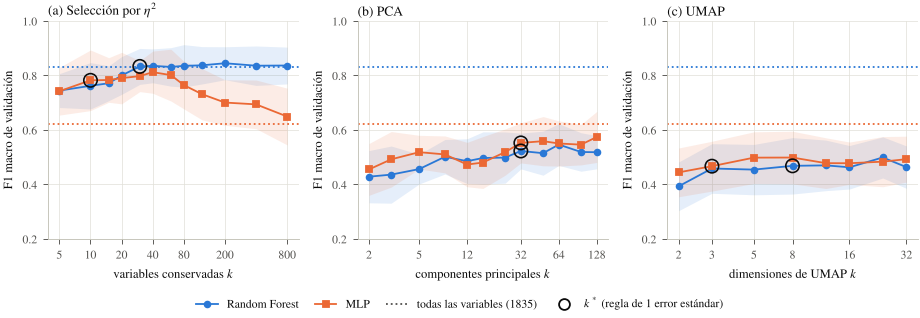

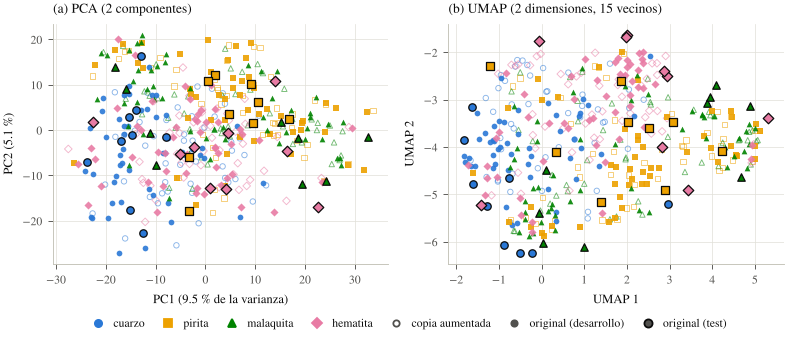

In [25]:
fig = fig_reduction.make({"sel": r_sel, "pca": r_pca, "umap": r_umap}, s3)
F.save(fig, "fig_reduction", close=False); plt.show()
fig = fig_embed.make(d)
F.save(fig, "fig_embed", close=False); plt.show()

**Discusión.** Para los dos modelos el orden de las representaciones es el mismo: **selección por η² ≳ todas las variables > PCA ≳ UMAP** (la tabla, la figura de arriba y la celda siguiente dan las cifras exactas, con diferencias pareadas e intervalos de confianza).

* **Selección por η² (filtro supervisado).** Con unas treinta variables el Random Forest iguala el F1 de validación de las 1835 variables (la diferencia pareada es compatible con cero) y el MLP *mejora* de forma significativa, porque al descartar las variables HOG ruidosas sobreajusta menos. Conservar *todas* las variables significativas no redundantes (556 por pliegue en promedio, casi todas HOG) ya no ayuda (Random Forest 0.826; MLP 0.680): lo que aporta es el pequeño grupo de descriptores muy discriminantes (color, GLCM, LBP y Gabor).
* **PCA (lineal, no supervisado).** Reduce más del 98 % de la dimensión, pero degrada de forma significativa al Random Forest y deja al MLP por debajo de su línea base (−0.07; diferencia no concluyente). Ningún número de componentes explorado (hasta 128, que explican el 84.5 % de la varianza en el ajuste final) recupera el desempeño. *La varianza no es discriminación*: las 71 variables compactas aportan solo el 3.9 % de la varianza total y no dominan ninguna de las primeras componentes (en las 32 primeras, el 97 % de la norma de las cargas corresponde a variables HOG; sería el 96 % si todas pesaran igual); la componente con mayor η² (la primera, η² = 0.232) discrimina menos de la mitad que la mejor variable individual (η² = 0.515).
* **UMAP (no lineal, no supervisado).** El desempeño es plano en todo el rango de dimensiones y similar al de k-NN. UMAP preserva la vecindad euclídea de las 1835 variables estandarizadas, y esa vecindad es poco informativa (la proporción de los 15 vecinos de la misma clase es ≈ 0.37, frente a 0.57 con solo las 71 variables no HOG; azar: 0.25); no puede crear una separación que su grafo no contiene.
* **Modelo recomendado.** Random Forest con las 30 variables de mayor η² (3 HOG, 10 de color, 3 Gabor, 5 LBP y 9 GLCM): iguala a las 1835 variables en validación (F1 0.833 frente a 0.832) con 98.4 % menos variables; en prueba obtiene F1 0.750 frente a 0.779, diferencia que con 36 imágenes no es concluyente.
* **Salvedades.** (i) $k^*$ e hiperparámetros se eligen con la misma validación con la que se reportan (optimismo leve, el mismo para las tres técnicas); (ii) la prueba (36 imágenes) confirma el orden pero con intervalos que se solapan; (iii) UMAP se ejecutó con una implementación propia (verificada arriba con *digits*).

In [26]:
def f1_of(tech_res, m):
    sm = tech_res["summary"][m]; return [x for x in sm["per_k"] if x["k"] == sm["k_1se"]][0]
for m in r_sel["models"]:
    base = s3[m]["val"]["f1_m"]
    print(f"{m}: todas las variables F1 = {base[0]:.3f} ± {base[1]:.3f}   (prueba: F1 = {s3[m]['test_f1']:.3f})")
    for nom, res in (("selección", r_sel), ("PCA", r_pca), ("UMAP", r_umap)):
        x = f1_of(res, m)
        print(f"   {nom:10s} k* = {x['k']:4d} ({100 * (1835 - x['k']) / 1835:5.1f} % menos)  F1 = {x['f1_mean']:.3f} ± {x['f1_ci']:.3f}   |  prueba: F1 = {res['summary'][m]['final']['test_f1']:.3f}")
print("\nDiferencias pareadas de F1 entre técnicas (en el k* de cada una; IC95 de Nadeau-Bengio):")
for m in r_sel["models"]:
    for a, b, na, nb in ((r_sel, r_pca, "selección", "PCA"), (r_sel, r_umap, "selección", "UMAP"), (r_pca, r_umap, "PCA", "UMAP")):
        print(f"   {m:14s} {na:10s} − {nb:5s}:", paired(f1_of(a, m)["f1"], f1_of(b, m)["f1"]))

Random Forest: todas las variables F1 = 0.832 ± 0.063   (prueba: F1 = 0.779)
   selección  k* =   30 ( 98.4 % menos)  F1 = 0.833 ± 0.066   |  prueba: F1 = 0.750
   PCA        k* =   32 ( 98.3 % menos)  F1 = 0.523 ± 0.066   |  prueba: F1 = 0.606
   UMAP       k* =    8 ( 99.6 % menos)  F1 = 0.468 ± 0.104   |  prueba: F1 = 0.497
MLP: todas las variables F1 = 0.622 ± 0.106   (prueba: F1 = 0.659)
   selección  k* =   10 ( 99.5 % menos)  F1 = 0.782 ± 0.111   |  prueba: F1 = 0.745
   PCA        k* =   32 ( 98.3 % menos)  F1 = 0.552 ± 0.074   |  prueba: F1 = 0.439
   UMAP       k* =    3 ( 99.8 % menos)  F1 = 0.467 ± 0.091   |  prueba: F1 = 0.556

Diferencias pareadas de F1 entre técnicas (en el k* de cada una; IC95 de Nadeau-Bengio):
   Random Forest  selección  − PCA  : +0.311 ± 0.077  (significativa)
   Random Forest  selección  − UMAP : +0.365 ± 0.111  (significativa)
   Random Forest  PCA        − UMAP : +0.054 ± 0.072  (no concluyente)
   MLP            selección  − PCA  : +0.230 ± 0.11

---
## 6. Conclusiones

**Objetivos.**
* **(O1)** Se caracterizó la base (432 filas × 1835 variables numéricas, sin datos faltantes, cuatro clases balanceadas; análisis exploratorio en 1.B) y se justificó el aprendizaje supervisado de clasificación multiclase (1.C).
* **(O2)** Se compararon cinco modelos (regresión logística, k-NN, Random Forest, MLP y SVM) con 120 configuraciones de hiperparámetros: el **Random Forest es el mejor** (F1 de validación 0.832 ± 0.063; ventaja significativa sobre el MLP, +0.210 ± 0.103), porque solo el 3.9 % de las variables (las 71 no HOG) es informativo y las 1764 HOG perjudican a los modelos que usan todas las variables por igual; los IC del MLP, la regresión logística y la SVM se solapan ampliamente (las diferencias pareadas entre ellos no son concluyentes) y k-NN es el peor. Todos los modelos salvo k-NN alcanzan F1 de entrenamiento 1.00 (sobreajuste que la regularización de las mallas no elimina).
* **(O3)** La reducción **supervisada** por η² conserva el desempeño con ≈ 30 variables (≈ 98 % menos) y mejora al MLP; PCA y UMAP, **no supervisados**, lo degradan de forma significativa porque la varianza y la vecindad están dominadas por las 1764 variables HOG.

**Hallazgos metodológicos.** La validación con fuga de información (copias aumentadas repartidas al azar entre entrenamiento y validación) sobreestima el F1 hasta ≈ 0.16 puntos y no concuerda con la prueba; la aumentación solo mejora de forma significativa al Random Forest; y los intervalos de confianza (Nadeau–Bengio en validación; Wilson y *bootstrap* en prueba) evitan sobreinterpretar diferencias que no son concluyentes.

**Limitaciones.** (i) La prueba tiene 36 imágenes (IC ≈ ±0.13): las decisiones se apoyan en la validación (204 imágenes × 15 particiones). (ii) Las imágenes de prueba provienen de la misma fuente que las de entrenamiento y no se verificó si el banco contiene imágenes casi duplicadas; con otra fuente de fotografías el desempeño puede ser menor (en la literatura revisada cae de 90.7 % a 80.2 %). (iii) Hiperparámetros y $k^*$ se eligen con la misma validación con la que se reportan (optimismo leve). (iv) UMAP se ejecutó con una implementación propia.

**Trabajo futuro.** Medir el cambio de dominio con un conjunto de prueba propio (fotografías de otro dispositivo); reemplazar HOG por incrustaciones de una red convolucional preentrenada; comparar el filtro por η² con otros métodos supervisados (importancia del Random Forest, PLS-DA, UMAP supervisado).

Las cifras de este cuaderno son exactamente las del informe: `src/make_report_assets.py` genera desde `results/cache` los archivos `informe/latex/numeros.tex` y `informe/latex/tablas/*.tex` que el informe incluye (se ejecuta en la celda siguiente).

In [27]:
R.main()          # escribe informe/latex/numeros.tex, informe/latex/tablas/*.tex y results/*.csv a partir de los resultados de este cuaderno
print("Archivos generados:", sorted(p.name for p in (P.REPORT / "tablas").glob("*.tex")), "+ numeros.tex")

listo: 423 cifras; ['g', 'pca', 's2', 's3', 'sel', 'umap']
Archivos generados: ['tab_grids.tex', 'tab_individual.tex', 'tab_reduccion.tex', 'tab_resultados.tex'] + numeros.tex


---
## 7. Reproducibilidad

* **Semillas:** `SEED = 2026` (particiones, bosques, MLP, UMAP, *bootstrap*). Mismos datos + mismas versiones ⇒ mismos resultados; con otras versiones de las librerías pueden aparecer diferencias numéricas pequeñas.
* **Recalcular desde cero:** poner `FORCE = True` en la primera celda (o `python src/run_stage.py grids|final|sel|pca|umap --force`); del orden de 35 min con 2 núcleos (evaluación final ≈ 2 min, selección ≈ 7 min, PCA ≈ 5 min y UMAP ≈ 7 min medidos por etapa; mallas ≈ 8 min, estimado).
* **Verificación:** `python src/verificar_reproducibilidad.py grids final sel pca umap` recalcula desde cero, en una carpeta temporal, las mallas de la regresión logística y de k-NN (completas) y la mejor configuración de Random Forest, MLP y SVM, la evaluación final de los cinco modelos y las tres reducciones, y las compara con `results/cache`. En la ejecución con la que se entregó el proyecto, todas las cantidades comparadas coincidieron exactamente (diferencia máxima 0.0).
* **Limitaciones principales:** prueba de solo 36 imágenes (IC anchos); imágenes de prueba de la misma fuente que las de entrenamiento (no mide cambio de dominio); posibles imágenes casi duplicadas en el banco no verificadas; el mejor modelo de cada familia se elige con la misma validación (ligero optimismo, por eso se reporta también la prueba).

In [28]:
print(f"Tiempo total de esta ejecución: {time.time() - T0:.0f} s | FORCE = {FORCE}")
print("Versiones:", "Python", platform.python_version(), "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)

Tiempo total de esta ejecución: 16 s | FORCE = False
Versiones: Python 3.13.18 | numpy 2.5.3 | scikit-learn 1.9.1
